### 🔁 Iterative Retrieval + Self-Reflection (Groq + HuggingFace)
1. Retrieve docs and **accumulate** them across iterations (de-duplicated)
2. Generate an answer grounded ONLY in the context
3. A critic checks the answer **against the context**: grounded? complete? what's missing?
4. If not good: write a short, focused search query from the critic's feedback and retrieve again
5. Stop when verified, or when the attempt limit is hit (then say what's missing honestly)

In [16]:
import os
from dotenv import load_dotenv
load_dotenv()
os.environ["GROQ_API_KEY"] = os.getenv("groq_api")

      

In [17]:
from typing import List
from pydantic import BaseModel, Field

from langchain_core.documents import Document
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.document_loaders import TextLoader
from langchain_community.vectorstores import FAISS

from langchain_groq import ChatGroq
from langchain_huggingface import HuggingFaceEmbeddings

from langgraph.graph import StateGraph, END

In [18]:
GROQ_MODEL = "openai/gpt-oss-20b"   # "groq:" prefix nahi lagana

llm = ChatGroq(model=GROQ_MODEL, temperature=0)
embeddings = HuggingFaceEmbeddings(
    model_name="sentence-transformers/all-MiniLM-L6-v2"
)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

In [19]:
internal_docs = """Internal Engineering Report: Transformer Variants in Production
=====================================================================

Overview:
This document summarizes the transformer-based models currently used or evaluated
across our production systems, along with deployment architecture, optimizations
and lessons learned.

Transformer Variants in Production:

1. EfficientFormer:
   - Deployed for on-device image classification in the mobile app.
   - Chosen for low latency (under 2 ms on iPhone 12 Neural Engine).
   - Converted to Core ML and ONNX for cross-platform inference.
   - Replaced MobileViT after A/B tests showed 18% faster inference.

2. DistilBERT:
   - Used for semantic search over internal support tickets.
   - 40% smaller than BERT-base with about 97% of its accuracy on our benchmark.
   - Served behind a FastAPI microservice with Redis caching.
   - Being phased out for intent tasks in favour of TinyBERT due to memory limits.

3. Reformer:
   - Tested for memory efficiency on embedded devices.
   - LSH attention led to 60% memory reduction.
   - Integration challenges with standard transformers due to bucket collisions.
   - Ongoing investigation for training stability and gradient clipping strategies.

4. LLaMA2:
   - Integrated with proprietary instruction-tuned layer.
   - Combined with domain-specific knowledge graphs.
   - Used as base model in chat deployment.
   - Prompt format adapted with multi-turn chat memory and RAG backend.
   - Experimented with LLaMAIndex and LangGraph-based orchestration.

5. TinyBERT:
   - Fine-tuned for classification tasks on internal email triage system.
   - Integrated into Outlook plugin via TensorFlow Lite.

Deployment Architecture:

- Models are served through NVIDIA Triton Inference Server with dynamic batching.
- GPU inference runs on AWS EKS node groups with A10G instances.
- CPU-only models (TinyBERT, DistilBERT) run on autoscaled Fargate tasks.
- Vector search uses FAISS indexes rebuilt nightly from the document store.
- Monitoring with Prometheus and Grafana; latency SLO is p95 under 300 ms.

Optimizations:

- Distillation of teacher-student models using response alignment
- Knowledge injection via adapters
- Mixed-precision training (AMP) with Nvidia A100s
- Use of DVC and MLflow for experiment tracking
- Canary rollout strategy for model updates
- CI/CD: GitHub Actions → Docker → EKS with Helm charts

Additional Notes:

- Vision transformers (ViT and Swin Transformer) evaluated in manufacturing QC tasks.
- Speech transformers (Wav2Vec 2.0) benchmarked for voice assistant integrations.
- Tokenizers: SentencePiece, BPE, and unigram tokenizers compared for multilingual tasks.
- Significant improvements noted with FlashAttention and Rotary Positional Encoding.
"""

with open("internal_docs.txt", "w", encoding="utf-8") as f:
    f.write(internal_docs)

print("internal_docs.txt created:", len(internal_docs), "characters")

internal_docs.txt created: 2775 characters


In [20]:
docs = TextLoader("internal_docs.txt", encoding="utf-8").load()
chunks = RecursiveCharacterTextSplitter(
    chunk_size=500, chunk_overlap=50
).split_documents(docs)

vectorstore = FAISS.from_documents(chunks, embeddings)
retriever = vectorstore.as_retriever(search_kwargs={"k": 4})
print(f"Chunks indexed: {len(chunks)}")

Chunks indexed: 8


In [21]:
MAX_ATTEMPTS = 3

class IterativeRAGState(BaseModel):
    question: str
    refined_question: str = ""
    queries_tried: List[str] = []          # avoid repeating the same search
    retrieved_docs: List[Document] = []    # ACCUMULATED across iterations
    answer: str = ""
    feedback: str = ""                     # critic's notes, passed to refine + answer
    verified: bool = False
    attempts: int = 0


class Verdict(BaseModel):
    grounded: bool = Field(description="True if every claim in the answer is supported by the context")
    complete: bool = Field(description="True if the context-based answer fully addresses the question")
    missing_info: str = Field(description="What information is missing or unsupported. Empty if nothing.")

class SearchQuery(BaseModel):
    query: str = Field(description="A short keyword-style search query, max 15 words")

critic = llm.with_structured_output(Verdict)
query_writer = llm.with_structured_output(SearchQuery)

In [22]:
def retrieve_docs(state: IterativeRAGState):
    query = state.refined_question or state.question
    new_docs = retriever.invoke(query)

    seen = {d.page_content for d in state.retrieved_docs}
    added = [d for d in new_docs if d.page_content not in seen]

    print(f"🔎 Query: {query!r} -> {len(added)} new docs (total {len(state.retrieved_docs) + len(added)})")
    return {
        "retrieved_docs": state.retrieved_docs + added,
        "queries_tried": state.queries_tried + [query],
    }

In [23]:
def generate_answer(state: IterativeRAGState):
    context = "\n\n".join(d.page_content for d in state.retrieved_docs)
    feedback_block = (
        f"\nA reviewer found this problem in your previous answer:\n{state.feedback}\n"
        if state.feedback else ""
    )
    prompt = f"""Answer the question using ONLY the context below.
- Do not use outside knowledge.
- Do not invent connections that the context does not state.
- If the context does not contain the answer (or part of it), clearly say what is missing.
{feedback_block}
Context:
{context}

Question:
{state.question}"""
    response = llm.invoke(prompt).content.strip()
    return {"answer": response, "attempts": state.attempts + 1}

In [24]:
def reflect_on_answer(state: IterativeRAGState):
    context = "\n\n".join(d.page_content for d in state.retrieved_docs)
    prompt = f"""You are a strict reviewer for a RAG system.
Judge the answer ONLY against the context. Ignore your own knowledge.
An answer that honestly says "the context does not cover X" is grounded.

Context:
{context}

Question: {state.question}
Answer: {state.answer}"""
    v: Verdict = critic.invoke(prompt)
    verified = v.grounded and v.complete
    print(f"🪞 Attempt {state.attempts}: grounded={v.grounded}, complete={v.complete}")
    return {"verified": verified, "feedback": v.missing_info}

In [25]:
def refine_query(state: IterativeRAGState):
    prompt = f"""Write ONE short search query to find the missing information.

Original question: {state.question}
What is missing: {state.feedback}
Queries already tried (do not repeat them): {state.queries_tried}"""
    q: SearchQuery = query_writer.invoke(prompt)
    return {"refined_question": q.query.strip()}

In [26]:
def route_after_reflect(state: IterativeRAGState) -> str:
    if state.verified or state.attempts >= MAX_ATTEMPTS:
        return "end"
    return "refine"


builder = StateGraph(IterativeRAGState)

builder.add_node("retrieve", retrieve_docs)
builder.add_node("answer", generate_answer)
builder.add_node("reflect", reflect_on_answer)
builder.add_node("refine", refine_query)

builder.set_entry_point("retrieve")
builder.add_edge("retrieve", "answer")
builder.add_edge("answer", "reflect")          # only ONE outgoing edge from answer
builder.add_conditional_edges(
    "reflect",
    route_after_reflect,
    {"end": END, "refine": "refine"},
)
builder.add_edge("refine", "retrieve")

graph = builder.compile()

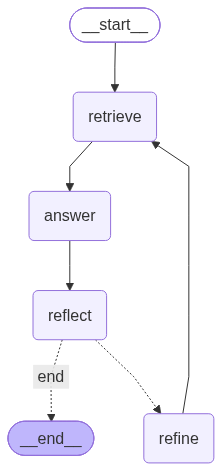

In [27]:
from IPython.display import Image, display
try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as e:
    print("Diagram render failed (needs internet):", e)

In [28]:
query = "agent loops and transformer-based systems?"
final = graph.invoke(IterativeRAGState(question=query))

print("\n✅ Final Answer:\n", final["answer"])
print("\n🧠 Verified:", final["verified"])
print("🔁 Attempts:", final["attempts"])
print("🔎 Queries tried:", *final["queries_tried"], sep="\n  - ")
if not final["verified"]:
    print("\n⚠️ Still missing:", final["feedback"])

🔎 Query: 'agent loops and transformer-based systems?' -> 4 new docs (total 4)
🪞 Attempt 1: grounded=True, complete=True

✅ Final Answer:
 The provided context does not contain any information about “agent loops” or how they relate to transformer‑based systems. Therefore, I cannot answer that question based on the given text.

🧠 Verified: True
🔁 Attempts: 1
🔎 Queries tried:
  - agent loops and transformer-based systems?
